In [1]:
# Data handling and visualization
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning models and evaluation
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression

# NLP preprocessing
import re
import nltk
nltk.download('stopwords')
from nltk.corpus import stopwords


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
dataset_path = '/content/drive/MyDrive/Dataset.csv'

df = pd.read_csv(dataset_path)

df.head()


,Unnamed: 0,text,Emotion
0,0,i seriously hate one subject to death but now ...,hate
1,1,im so full of life i feel appalled,neutral
2,2,i sit here to write i start to dig out my feel...,neutral
3,3,ive been really angry with r and i feel like a...,anger
4,4,i feel suspicious if there is no one outside l...,neutral


In [4]:
# Drop unwanted column if already loaded
if 'Unnamed: 0' in df.columns:
    df = df.drop('Unnamed: 0', axis=1)

# Display first rows
df.head()


,text,Emotion
0,i seriously hate one subject to death but now ...,hate
1,im so full of life i feel appalled,neutral
2,i sit here to write i start to dig out my feel...,neutral
3,ive been really angry with r and i feel like a...,anger
4,i feel suspicious if there is no one outside l...,neutral


Dataset Shape: (839555, 2)
Unique Emotions: ['hate' 'neutral' 'anger' 'love' 'worry' 'relief' 'happiness' 'fun'
 'empty' 'enthusiasm' 'sadness' 'surprise' 'boredom']


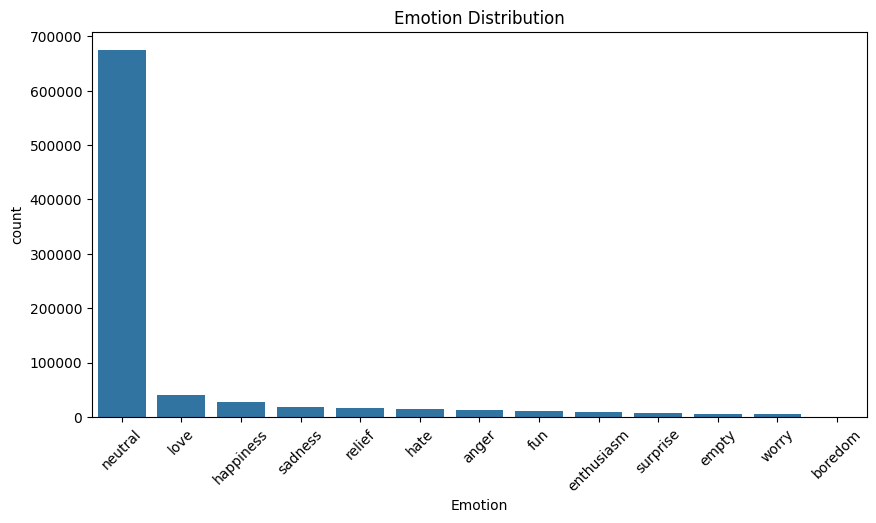

In [5]:
# Print dataset shape and unique emotion labels
print("Dataset Shape:", df.shape)
print("Unique Emotions:", df['Emotion'].unique())

# Plot distribution of emotions
plt.figure(figsize=(10,5))
sns.countplot(data=df, x='Emotion', order=df['Emotion'].value_counts().index)
plt.xticks(rotation=45)
plt.title("Emotion Distribution")
plt.show()


In [6]:
# Check for missing values
print("Missing values in each column:")
print(df.isnull().sum())

# Drop rows with missing text or emotion
df = df.dropna(subset=['text', 'Emotion'])
print("After removing missing values, dataset shape:", df.shape)


Missing values in each column:
text       0
Emotion    0
dtype: int64
After removing missing values, dataset shape: (839555, 2)


In [7]:
# Remove duplicate rows
num_duplicates = df.duplicated().sum()
print("Number of duplicate rows:", num_duplicates)
df = df.drop_duplicates()
print("After removing duplicates, dataset shape:", df.shape)

Number of duplicate rows: 445733
After removing duplicates, dataset shape: (393822, 2)


In [8]:
# Remove extremely short or long texts
df['text_length'] = df['text'].apply(lambda x: len(str(x).split()))
df = df[(df['text_length'] >= 2) & (df['text_length'] <= 200)]
df.drop('text_length', axis=1, inplace=True)
print("After removing noisy texts, dataset shape:", df.shape)

After removing noisy texts, dataset shape: (393804, 2)


In [9]:
# Load stopwords
stop_words = set(stopwords.words('english'))

# Preprocessing function
def preprocess_text(text):
    text = text.lower()
    text = re.sub(r"http\S+|www\S+|https\S+", '', text)
    text = re.sub(r'\@\w+|\#','', text)
    text = re.sub(r'[^a-z\s]', '', text)
    tokens = [word for word in text.split() if word not in stop_words]
    return " ".join(tokens)

# Apply preprocessing to 'text' column
df['text'] = df['text'].apply(preprocess_text)
df.head()


,text,Emotion
0,seriously hate one subject death feel reluctan...,hate
1,im full life feel appalled,neutral
2,sit write start dig feelings think afraid acce...,neutral
3,ive really angry r feel like idiot trusting fi...,anger
4,feel suspicious one outside like rapture happe...,neutral


In [10]:
# Features and labels
X = df['text']
y = df['Emotion']

# Encode labels
le = LabelEncoder()
y_enc = le.fit_transform(y)

# Split into train/test sets (70/30)
X_train, X_test, y_train, y_test = train_test_split(
    X, y_enc, test_size=0.3, random_state=42, stratify=y_enc
)

print("Train size:", len(X_train), "| Test size:", len(X_test))
print("Number of classes:", len(le.classes_))
print("Classes:", le.classes_)


Train size: 275662 | Test size: 118142
Number of classes: 13
Classes: ['anger' 'boredom' 'empty' 'enthusiasm' 'fun' 'happiness' 'hate' 'love'
 'neutral' 'relief' 'sadness' 'surprise' 'worry']


In [11]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Convert text to TF-IDF features
vectorizer = TfidfVectorizer(max_features=5000)
X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)


In [12]:
# Define models dictionary
models = {
    "Naive Bayes": MultinomialNB(),
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
}


In [14]:
# Train each model
for name, model in models.items():
    print(f"=== Training {name} ===")
    model.fit(X_train_vec, y_train)
    print(f"{name} training completed.\n")


=== Training Naive Bayes ===
Naive Bayes training completed.

=== Training Logistic Regression ===
Logistic Regression training completed.



In [15]:
# Print classification reports
for name, model in models.items():
    print(f"=== {name} Classification Report ===")
    y_pred = model.predict(X_test_vec)
    print(classification_report(y_test, y_pred, target_names=le.classes_))


=== Naive Bayes Classification Report ===
              precision    recall  f1-score   support

       anger       0.95      0.32      0.48      1786
     boredom       0.00      0.00      0.00        18
       empty       1.00      0.27      0.42       809
  enthusiasm       1.00      0.35      0.52      1349
         fun       0.95      0.26      0.41      1456
   happiness       0.95      0.45      0.61      3912
        hate       0.98      0.35      0.52      1848
        love       0.94      0.51      0.66      5290
     neutral       0.87      1.00      0.93     95076
      relief       0.96      0.31      0.47      2402
     sadness       0.97      0.50      0.66      2545
    surprise       0.99      0.29      0.44      1029
       worry       1.00      0.06      0.12       622

    accuracy                           0.88    118142
   macro avg       0.89      0.36      0.48    118142
weighted avg       0.89      0.88      0.86    118142

=== Logistic Regression Classificatio

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


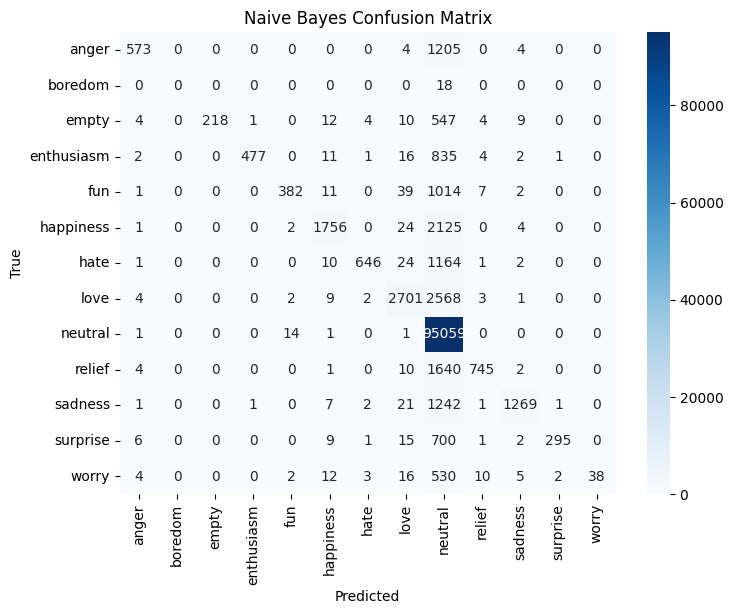

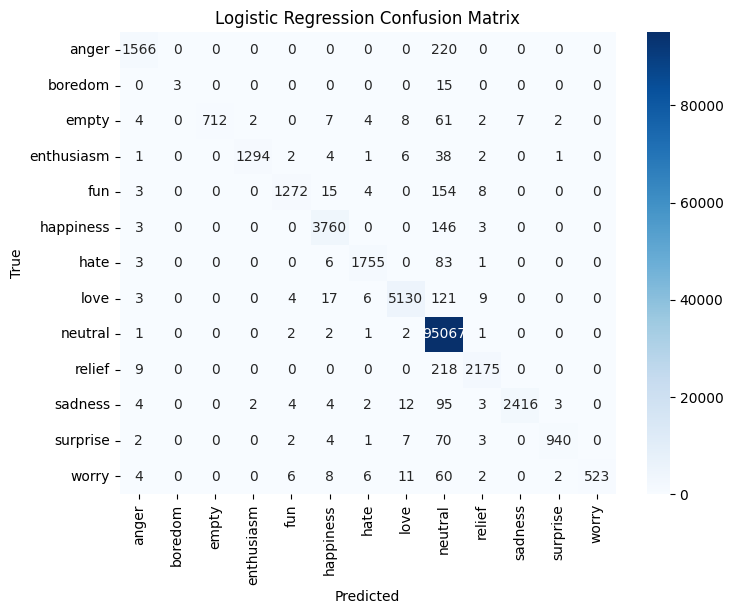

In [16]:
# Plot confusion matrices
for name, model in models.items():
    y_pred = model.predict(X_test_vec)
    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(8,6))
    sns.heatmap(cm, annot=True, fmt='d', xticklabels=le.classes_, yticklabels=le.classes_, cmap='Blues')
    plt.title(f"{name} Confusion Matrix")
    plt.xlabel('Predicted')
    plt.ylabel('True')
    plt.show()


In [18]:
import joblib

# Save models and vectorizer
joblib.dump(models['Naive Bayes'], "naive_bayes_model.pkl")
joblib.dump(models['Logistic Regression'], "logreg_model.pkl")
joblib.dump(vectorizer, "tfidf_vectorizer.pkl")
joblib.dump(le, "label_encoder.pkl")

print("Models, vectorizer, and label encoder saved successfully!")


Models, vectorizer, and label encoder saved successfully!
